problema: es posible saber si mi conjunto de datos permite predecir la clase "benigno o maligno" que los modelos no han visto existe algun patron que lo prediga sengun los valores en las columnas ? 
motivacion: mi evaluacion mostrara cuantas muestras clasifica correctamente cada modelo y en particulas cuantas muestreas malignas clasifica por error como benigna 
pregunta de investigacion: quiero saber cual de los modelos, regresion logistica o random fores logra mayor accuracy y si esa ventaja se mantiene en las tres particiones.

In [1]:
import pandas as pd 
import numpy as np 

In [2]:
df = pd.read_csv("breast-cancer-wisconsin.data",header=None) #tuve que ocupar None porque mi data no contiene el encabezado 

In [3]:
df.head()

,0,1,2,3,4,5,6,7,8,9,10
0,1000025,5,1,1,1,2,1,3,1,1,2
1,1002945,5,4,4,5,7,10,3,2,1,2
2,1015425,3,1,1,1,2,2,3,1,1,2
3,1016277,6,8,8,1,3,4,3,7,1,2
4,1017023,4,1,1,3,2,1,3,1,1,2


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 699 entries, 0 to 698
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   0       699 non-null    int64 
 1   1       699 non-null    int64 
 2   2       699 non-null    int64 
 3   3       699 non-null    int64 
 4   4       699 non-null    int64 
 5   5       699 non-null    int64 
 6   6       699 non-null    object
 7   7       699 non-null    int64 
 8   8       699 non-null    int64 
 9   9       699 non-null    int64 
 10  10      699 non-null    int64 
dtypes: int64(10), object(1)
memory usage: 60.2+ KB


In [5]:
df.shape

(699, 11)

In [6]:
df=df.rename(columns={0:"Sample code number",1:"Clump Thickness",2:"Uniformity of Cell Size",3:"Uniformity of Cell Shape",4:"Marginal Adhesion",5:"Single Epithelial Cell Size",6:"Bare Nuclei",7:"Bland Chromatin",8:"Normal Nucleoli",9:"Mitoses",10:"Class"})

In [7]:
df.head()

,Sample code number,Clump Thickness,Uniformity of Cell Size,Uniformity of Cell Shape,Marginal Adhesion,Single Epithelial Cell Size,Bare Nuclei,Bland Chromatin,Normal Nucleoli,Mitoses,Class
0,1000025,5,1,1,1,2,1,3,1,1,2
1,1002945,5,4,4,5,7,10,3,2,1,2
2,1015425,3,1,1,1,2,2,3,1,1,2
3,1016277,6,8,8,1,3,4,3,7,1,2
4,1017023,4,1,1,3,2,1,3,1,1,2


tuve que ejecutar rename ya que mi data venia sin encabezado, tuve que agregar los titulos desde datadiccionary. esto me ayudo a reconocer que cada columna muestra informacion relacionada a los tamañosn, formas y caracteristicas de las celulas. las cuales pueden ser benignas o malignas como muestra mi columna CLass (Target)   

In [8]:
df.isnull().sum()

Sample code number             0
Clump Thickness                0
Uniformity of Cell Size        0
Uniformity of Cell Shape       0
Marginal Adhesion              0
Single Epithelial Cell Size    0
Bare Nuclei                    0
Bland Chromatin                0
Normal Nucleoli                0
Mitoses                        0
Class                          0
dtype: int64

In [9]:
df["Sample code number"].unique()

array([ 1000025,  1002945,  1015425,  1016277,  1017023,  1017122,
        1018099,  1018561,  1033078,  1035283,  1036172,  1041801,
        1043999,  1044572,  1047630,  1048672,  1049815,  1050670,
        1050718,  1054590,  1054593,  1056784,  1057013,  1059552,
        1065726,  1066373,  1066979,  1067444,  1070935,  1071760,
        1072179,  1074610,  1075123,  1079304,  1080185,  1081791,
        1084584,  1091262,  1096800,  1099510,  1100524,  1102573,
        1103608,  1103722,  1105257,  1105524,  1106095,  1106829,
        1108370,  1108449,  1110102,  1110503,  1110524,  1111249,
        1112209,  1113038,  1113483,  1113906,  1115282,  1115293,
        1116116,  1116132,  1116192,  1116998,  1117152,  1118039,
        1120559,  1121732,  1121919,  1123061,  1124651,  1125035,
        1126417,  1131294,  1132347,  1133041,  1133136,  1136142,
        1137156,  1143978,  1147044,  1147699,  1147748,  1148278,
        1148873,  1152331,  1155546,  1156272,  1156948,  1157

In [10]:
df["Clump Thickness"].unique()

array([ 5,  3,  6,  4,  8,  1,  2,  7, 10,  9], dtype=int64)

In [11]:
df["Uniformity of Cell Size"].unique()

array([ 1,  4,  8, 10,  2,  3,  7,  5,  6,  9], dtype=int64)

In [12]:
df["Uniformity of Cell Shape"].unique()

array([ 1,  4,  8, 10,  2,  3,  5,  6,  7,  9], dtype=int64)

In [13]:
df["Marginal Adhesion"].unique()

array([ 1,  5,  3,  8, 10,  4,  6,  2,  9,  7], dtype=int64)

In [14]:
df["Single Epithelial Cell Size"].unique()

array([ 2,  7,  3,  1,  6,  4,  5,  8, 10,  9], dtype=int64)

In [15]:
df["Bare Nuclei"].unique()

array(['1', '10', '2', '4', '3', '9', '7', '?', '5', '8', '6'],
      dtype=object)

In [16]:
df["Bare Nuclei"].value_counts()

Bare Nuclei
1     402
10    132
2      30
5      30
3      28
8      21
4      19
?      16
9       9
7       8
6       4
Name: count, dtype: int64

In [17]:
faltantes = df["Bare Nuclei"]=="?" #debo conocer en que rows tengo dato faltante y segun mi feature categorical se si es  Benign: 458 (65.5%) Malignant: 241 (34.5%
df.loc[faltantes,"Class"]

23     4
40     2
139    2
145    2
158    2
164    2
235    2
249    2
275    2
292    4
294    2
297    2
315    2
321    2
411    2
617    2
Name: Class, dtype: int64

#debo comparar la cantidad de casos malignos entre los 699 filas originales y las 683 que quedarian si descarto esa fila. aunque la mayoria sea benigno.*lo que me ayudara a justificar la decision, es cuantos puntos porcentuales cambia la proporcion de malignos* 

In [18]:
df.loc[faltantes, "Class"].value_counts(normalize = True)*100

Class
2    87.5
4    12.5
Name: proportion, dtype: float64

In [19]:
#before 699 filas originales 
df["Class"].value_counts(normalize=True)*100

Class
2    65.522175
4    34.477825
Name: proportion, dtype: float64

In [20]:
df.loc[~faltantes,"Class"].value_counts(normalize=True)*100

Class
2    65.007321
4    34.992679
Name: proportion, dtype: float64

como podemos observar eliminar las filas es una decision razonable, representa solo el 2.3% de los registros y su exclusion cambia muy poco la proporcion de la clase. los casos malignos pasa de 34,48% a 34,99%

In [21]:
df["Bare Nuclei"] = df ["Bare Nuclei"].replace("?", np.nan)

In [22]:
df = df.dropna()
df.count()

Sample code number             683
Clump Thickness                683
Uniformity of Cell Size        683
Uniformity of Cell Shape       683
Marginal Adhesion              683
Single Epithelial Cell Size    683
Bare Nuclei                    683
Bland Chromatin                683
Normal Nucleoli                683
Mitoses                        683
Class                          683
dtype: int64

In [23]:
df["Bare Nuclei"] = df["Bare Nuclei"].astype("int64")

In [24]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 683 entries, 0 to 698
Data columns (total 11 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   Sample code number           683 non-null    int64
 1   Clump Thickness              683 non-null    int64
 2   Uniformity of Cell Size      683 non-null    int64
 3   Uniformity of Cell Shape     683 non-null    int64
 4   Marginal Adhesion            683 non-null    int64
 5   Single Epithelial Cell Size  683 non-null    int64
 6   Bare Nuclei                  683 non-null    int64
 7   Bland Chromatin              683 non-null    int64
 8   Normal Nucleoli              683 non-null    int64
 9   Mitoses                      683 non-null    int64
 10  Class                        683 non-null    int64
dtypes: int64(11)
memory usage: 64.0 KB


In [25]:
df.isnull().sum()

Sample code number             0
Clump Thickness                0
Uniformity of Cell Size        0
Uniformity of Cell Shape       0
Marginal Adhesion              0
Single Epithelial Cell Size    0
Bare Nuclei                    0
Bland Chromatin                0
Normal Nucleoli                0
Mitoses                        0
Class                          0
dtype: int64

In [26]:
df.shape

(683, 11)

luego de analizar la data decidi eliminar las filas de los datos faltantes para trabajar 

In [27]:
df["Bare Nuclei"].unique()

array([ 1, 10,  2,  4,  3,  9,  7,  5,  8,  6], dtype=int64)

In [28]:
df["Bland Chromatin"].unique()

array([ 3,  9,  1,  2,  4,  5,  7,  8,  6, 10], dtype=int64)

In [29]:
df["Normal Nucleoli"].unique()

array([ 1,  2,  7,  4,  5,  3, 10,  6,  9,  8], dtype=int64)

In [30]:
df["Mitoses"].unique()

array([ 1,  5,  4,  2,  3,  7, 10,  8,  6], dtype=int64)

In [31]:
df["Class"].unique()

array([2, 4], dtype=int64)

In [32]:
df.head()

,Sample code number,Clump Thickness,Uniformity of Cell Size,Uniformity of Cell Shape,Marginal Adhesion,Single Epithelial Cell Size,Bare Nuclei,Bland Chromatin,Normal Nucleoli,Mitoses,Class
0,1000025,5,1,1,1,2,1,3,1,1,2
1,1002945,5,4,4,5,7,10,3,2,1,2
2,1015425,3,1,1,1,2,2,3,1,1,2
3,1016277,6,8,8,1,3,4,3,7,1,2
4,1017023,4,1,1,3,2,1,3,1,1,2


In [33]:
df_new =df.drop(columns=["Sample code number"])

decido eliminar sample code number porque no tiene ninguna importancia en mi data. 

In [34]:
df_new.head()

,Clump Thickness,Uniformity of Cell Size,Uniformity of Cell Shape,Marginal Adhesion,Single Epithelial Cell Size,Bare Nuclei,Bland Chromatin,Normal Nucleoli,Mitoses,Class
0,5,1,1,1,2,1,3,1,1,2
1,5,4,4,5,7,10,3,2,1,2
2,3,1,1,1,2,2,3,1,1,2
3,6,8,8,1,3,4,3,7,1,2
4,4,1,1,3,2,1,3,1,1,2


In [35]:
label = df[["Class"]]

In [36]:
X = df_new           # Features (independent variables) from the Cancer dataset

y = label            # Target variable (Class) for the prediction

In [37]:
label.head()

,Class
0,2
1,2
2,2
3,2
4,2


In [38]:
y.value_counts()

Class
2        444
4        239
Name: count, dtype: int64

In [39]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, classification_report
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

In [40]:
from sklearn.tree import DecisionTreeClassifier, plot_tree       # Import Decision Tree Classifier and plot_tree 
from sklearn.model_selection import train_test_split             # Import train_test_split function
from sklearn import metrics                                      # Import scikit-learn metrics module for accuracy calculation
from sklearn import tree
import matplotlib.pyplot as plt

## Splitting Data 

In [41]:
# Split dataset in features and target variable
feature_cols = ['Clump Thickness', 'Uniformity of Cell Size', 'Uniformity of Cell Shape', 'Marginal Adhesion', 'Single Epithelial Cell Size', 'Bare Nuclei', 'Bland Chromatin',"Normal Nucleoli", 'Mitoses']
X = df[feature_cols]               # Features of the dataset
y = df.Class                       # Target variable of the dataset

# X = pima.iloc[:, :-1]              # All rows, all columns except the last
# y = pima.iloc[:, -1]               # All rows, only the last column

# X = pima.iloc[:, 0:8]
# y = pima.iloc[:, 8]

# Display the X and y arrays
print(X, y)

     Clump Thickness  Uniformity of Cell Size  Uniformity of Cell Shape  \
0                  5                        1                         1   
1                  5                        4                         4   
2                  3                        1                         1   
3                  6                        8                         8   
4                  4                        1                         1   
..               ...                      ...                       ...   
694                3                        1                         1   
695                2                        1                         1   
696                5                       10                        10   
697                4                        8                         6   
698                4                        8                         8   

     Marginal Adhesion  Single Epithelial Cell Size  Bare Nuclei  \
0                    1         

In [42]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.05, random_state = 1) # 5% training and 5% test

In [43]:
 #Create Decision Tree classifer object
clf = DecisionTreeClassifier(criterion = 'gini', max_depth = 3, random_state = 0)

# Train Decision Tree Classifer
clf = clf.fit(X_train, y_train)

#Predict the response for test dataset
y_pred = clf.predict(X_test)

In [44]:
# Example: y_pred is numpy array, y_test is pandas Series
# (just using your example variables)
# y_pred = np.array([...])
# y_test = df['label']   # for instance

# Combine into DataFrame
results = pd.DataFrame({
    "y_test (True)": y_test.reset_index(drop=True),  # reset index for alignment
    "y_pred (Predicted)": y_pred
})

# Show first 20 rows for a quick view
print(results.head(20))

# If you also want to check correctness
results["Correct?"] = results["y_test (True)"] == results["y_pred (Predicted)"]

print(results.head(20))

    y_test (True)  y_pred (Predicted)
0               2                   2
1               2                   2
2               2                   2
3               4                   4
4               2                   2
5               4                   4
6               2                   2
7               2                   2
8               4                   4
9               4                   4
10              2                   2
11              2                   2
12              4                   4
13              4                   4
14              2                   2
15              4                   4
16              2                   2
17              2                   4
18              2                   2
19              2                   2
    y_test (True)  y_pred (Predicted)  Correct?
0               2                   2      True
1               2                   2      True
2               2                   2      True
3         

## Evaluating Model

In [45]:
# Model Accuracy, how often is the classifier correct?
print("Accuracy:",metrics.accuracy_score(y_test, y_pred))

# Rounded upto 2 decimal places
print( "Accuracy: {:.2f}".format(metrics.accuracy_score(y_test, y_pred)) )

Accuracy: 0.9428571428571428
Accuracy: 0.94


In [46]:
X.columns.tolist()

['Clump Thickness',
 'Uniformity of Cell Size',
 'Uniformity of Cell Shape',
 'Marginal Adhesion',
 'Single Epithelial Cell Size',
 'Bare Nuclei',
 'Bland Chromatin',
 'Normal Nucleoli',
 'Mitoses']

In [47]:
df['Class'].unique().tolist()

[2, 4]

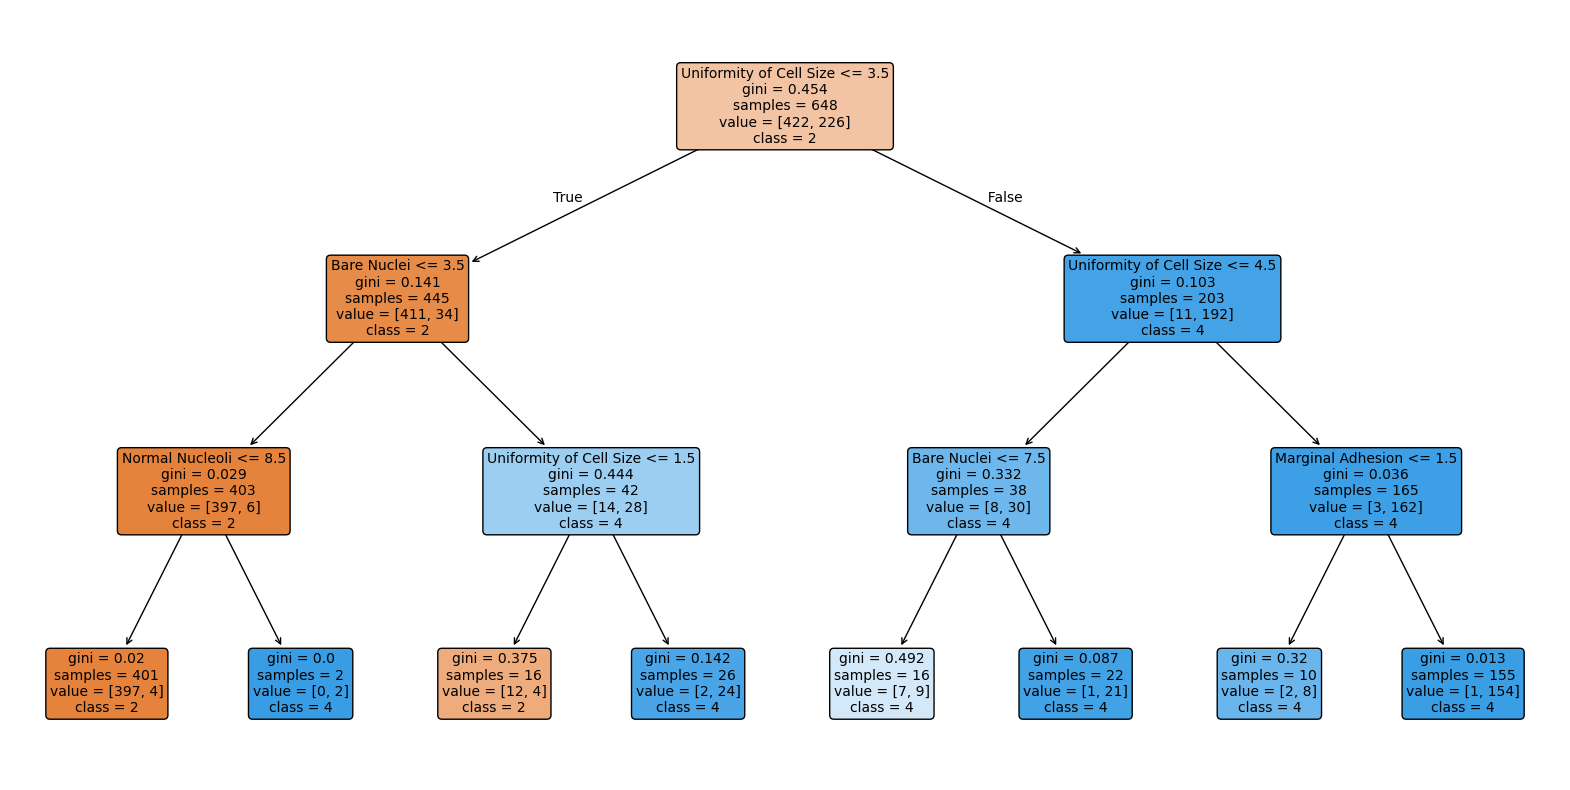

In [48]:
# Plot the Decision Tree
plt.figure(figsize = (20, 10))
plot_tree(clf, filled = True, feature_names = X.columns.tolist(), class_names = [str(label) for label in df['Class'].unique()], 
          rounded = True, fontsize = 10)
plt.show()

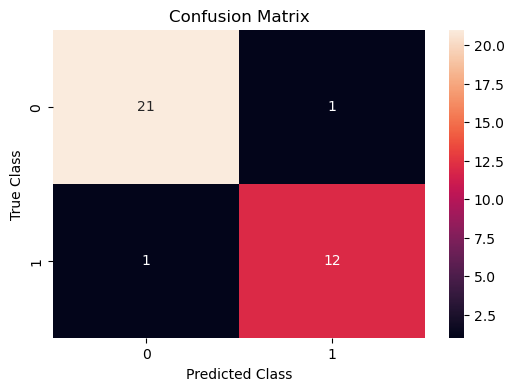

Classification Report:
              precision    recall  f1-score   support

           2       0.95      0.95      0.95        22
           4       0.92      0.92      0.92        13

    accuracy                           0.94        35
   macro avg       0.94      0.94      0.94        35
weighted avg       0.94      0.94      0.94        35



In [49]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

# Predict by using an object classifier 'clf'
y_predict = clf.predict(X_test)

# Calculate cm by using a method named as 'confusion_matrix'
cm = confusion_matrix(y_test, y_predict)

# Plot confusion matrix with integers using seaborn heatmap
plt.figure(figsize = (6, 4))
sns.heatmap(cm, annot = True, fmt = 'd')        # 'd' stands for integer format
plt.xlabel('Predicted Class')
plt.ylabel('True Class')
plt.title('Confusion Matrix')
plt.show()

# Generate classification report
report = classification_report(y_test, y_predict)
print("Classification Report:")
print(report)

In [50]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.15, random_state = 1) # 5% training and 5% test

In [51]:
 #Create Decision Tree classifer object
clf = DecisionTreeClassifier(criterion = 'gini', max_depth = 3, random_state = 0)

# Train Decision Tree Classifer
clf = clf.fit(X_train, y_train)

#Predict the response for test dataset
y_pred = clf.predict(X_test)

In [52]:
# Example: y_pred is numpy array, y_test is pandas Series
# (just using your example variables)
# y_pred = np.array([...])
# y_test = df['label']   # for instance

# Combine into DataFrame
results = pd.DataFrame({
    "y_test (True)": y_test.reset_index(drop=True),  # reset index for alignment
    "y_pred (Predicted)": y_pred
})

# Show first 20 rows for a quick view
print(results.head(20))

# If you also want to check correctness
results["Correct?"] = results["y_test (True)"] == results["y_pred (Predicted)"]

print(results.head(20))

    y_test (True)  y_pred (Predicted)
0               2                   2
1               2                   2
2               2                   2
3               4                   4
4               2                   2
5               4                   4
6               2                   2
7               2                   2
8               4                   4
9               4                   4
10              2                   2
11              2                   2
12              4                   4
13              4                   4
14              2                   2
15              4                   4
16              2                   2
17              2                   2
18              2                   2
19              2                   2
    y_test (True)  y_pred (Predicted)  Correct?
0               2                   2      True
1               2                   2      True
2               2                   2      True
3         

In [53]:
# Model Accuracy, how often is the classifier correct?
print("Accuracy:",metrics.accuracy_score(y_test, y_pred))

# Rounded upto 2 decimal places
print( "Accuracy: {:.2f}".format(metrics.accuracy_score(y_test, y_pred)) )

Accuracy: 0.9514563106796117
Accuracy: 0.95


In [54]:
X.columns.tolist()

['Clump Thickness',
 'Uniformity of Cell Size',
 'Uniformity of Cell Shape',
 'Marginal Adhesion',
 'Single Epithelial Cell Size',
 'Bare Nuclei',
 'Bland Chromatin',
 'Normal Nucleoli',
 'Mitoses']

In [55]:
df['Class'].unique().tolist()

[2, 4]

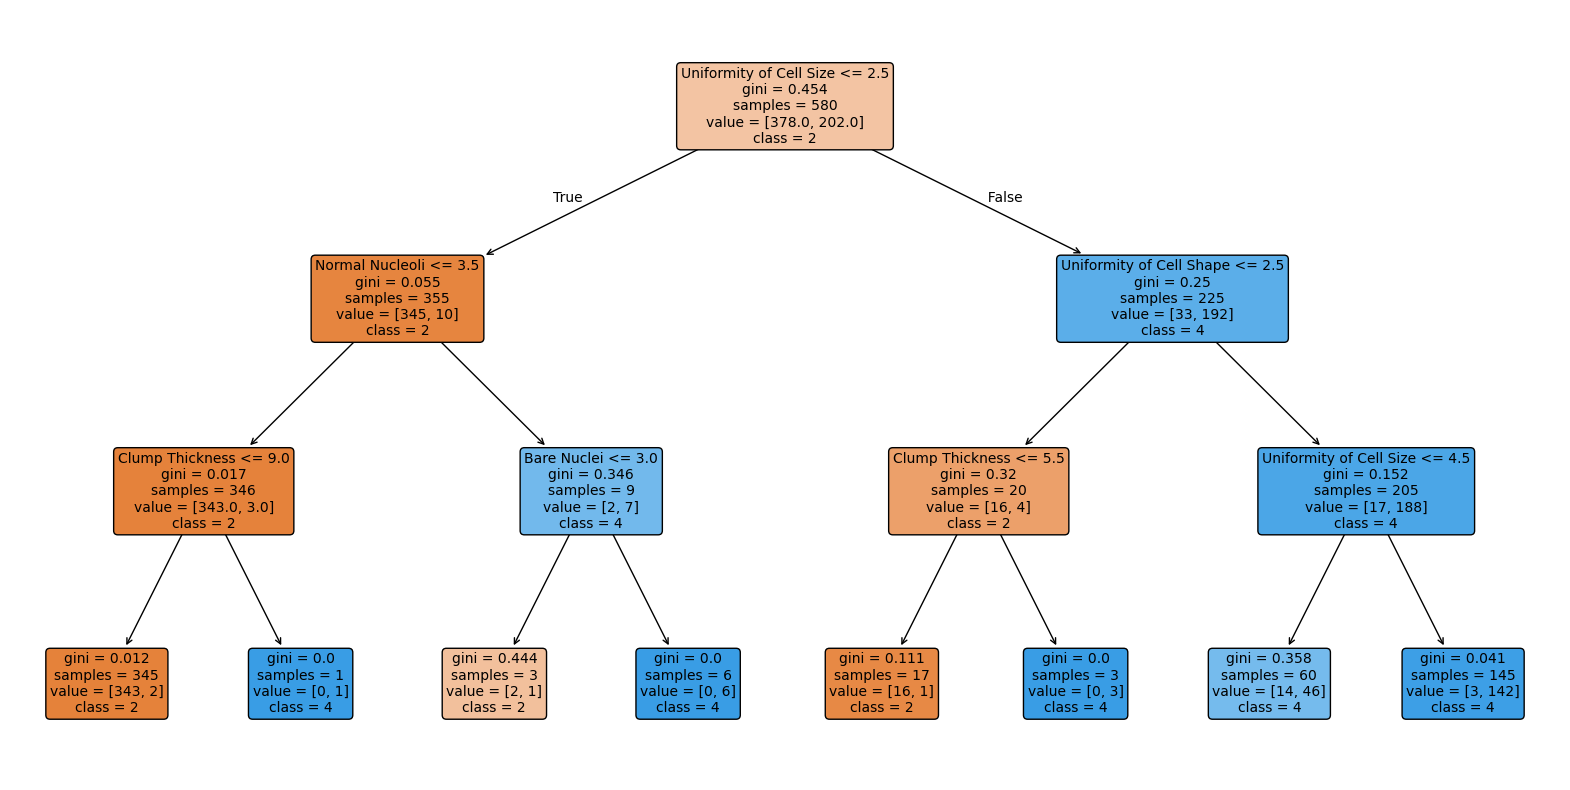

In [56]:
# Plot the Decision Tree
plt.figure(figsize = (20, 10))
plot_tree(clf, filled = True, feature_names = X.columns.tolist(), class_names = [str(label) for label in df['Class'].unique()], 
          rounded = True, fontsize = 10)
plt.show()

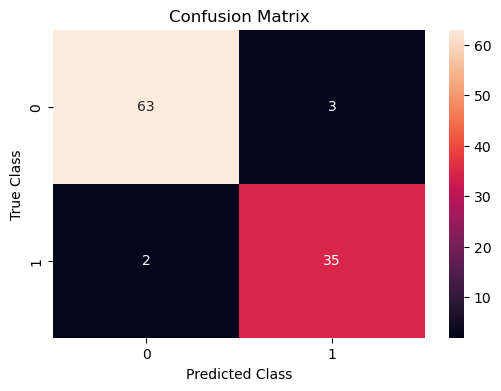

Classification Report:
              precision    recall  f1-score   support

           2       0.97      0.95      0.96        66
           4       0.92      0.95      0.93        37

    accuracy                           0.95       103
   macro avg       0.95      0.95      0.95       103
weighted avg       0.95      0.95      0.95       103



In [57]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

# Predict by using an object classifier 'clf'
y_predict = clf.predict(X_test)

# Calculate cm by using a method named as 'confusion_matrix'
cm = confusion_matrix(y_test, y_predict)

# Plot confusion matrix with integers using seaborn heatmap
plt.figure(figsize = (6, 4))
sns.heatmap(cm, annot = True, fmt = 'd')        # 'd' stands for integer format
plt.xlabel('Predicted Class')
plt.ylabel('True Class')
plt.title('Confusion Matrix')
plt.show()

# Generate classification report
report = classification_report(y_test, y_predict)
print("Classification Report:")
print(report)

In [58]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.25, random_state = 1) # 5% training and 5% test

In [59]:
#Create Decision Tree classifer object
clf = DecisionTreeClassifier(criterion = 'gini', max_depth = 3, random_state = 0)

# Train Decision Tree Classifer
clf = clf.fit(X_train, y_train)

#Predict the response for test dataset
y_pred = clf.predict(X_test)

In [60]:
# Example: y_pred is numpy array, y_test is pandas Series
# (just using your example variables)
# y_pred = np.array([...])
# y_test = df['label']   # for instance

# Combine into DataFrame
results = pd.DataFrame({
    "y_test (True)": y_test.reset_index(drop=True),  # reset index for alignment
    "y_pred (Predicted)": y_pred
})

# Show first 20 rows for a quick view
print(results.head(20))

# If you also want to check correctness
results["Correct?"] = results["y_test (True)"] == results["y_pred (Predicted)"]

print(results.head(20))

    y_test (True)  y_pred (Predicted)
0               2                   2
1               2                   2
2               2                   2
3               4                   4
4               2                   2
5               4                   4
6               2                   2
7               2                   2
8               4                   4
9               4                   4
10              2                   2
11              2                   2
12              4                   4
13              4                   4
14              2                   2
15              4                   4
16              2                   2
17              2                   2
18              2                   2
19              2                   2
    y_test (True)  y_pred (Predicted)  Correct?
0               2                   2      True
1               2                   2      True
2               2                   2      True
3         

In [61]:
# Model Accuracy, how often is the classifier correct?
print("Accuracy:",metrics.accuracy_score(y_test, y_pred))

# Rounded upto 2 decimal places
print( "Accuracy: {:.2f}".format(metrics.accuracy_score(y_test, y_pred)) )

Accuracy: 0.9590643274853801
Accuracy: 0.96


In [62]:
X.columns.tolist()

['Clump Thickness',
 'Uniformity of Cell Size',
 'Uniformity of Cell Shape',
 'Marginal Adhesion',
 'Single Epithelial Cell Size',
 'Bare Nuclei',
 'Bland Chromatin',
 'Normal Nucleoli',
 'Mitoses']

In [63]:
df['Class'].unique().tolist()

[2, 4]

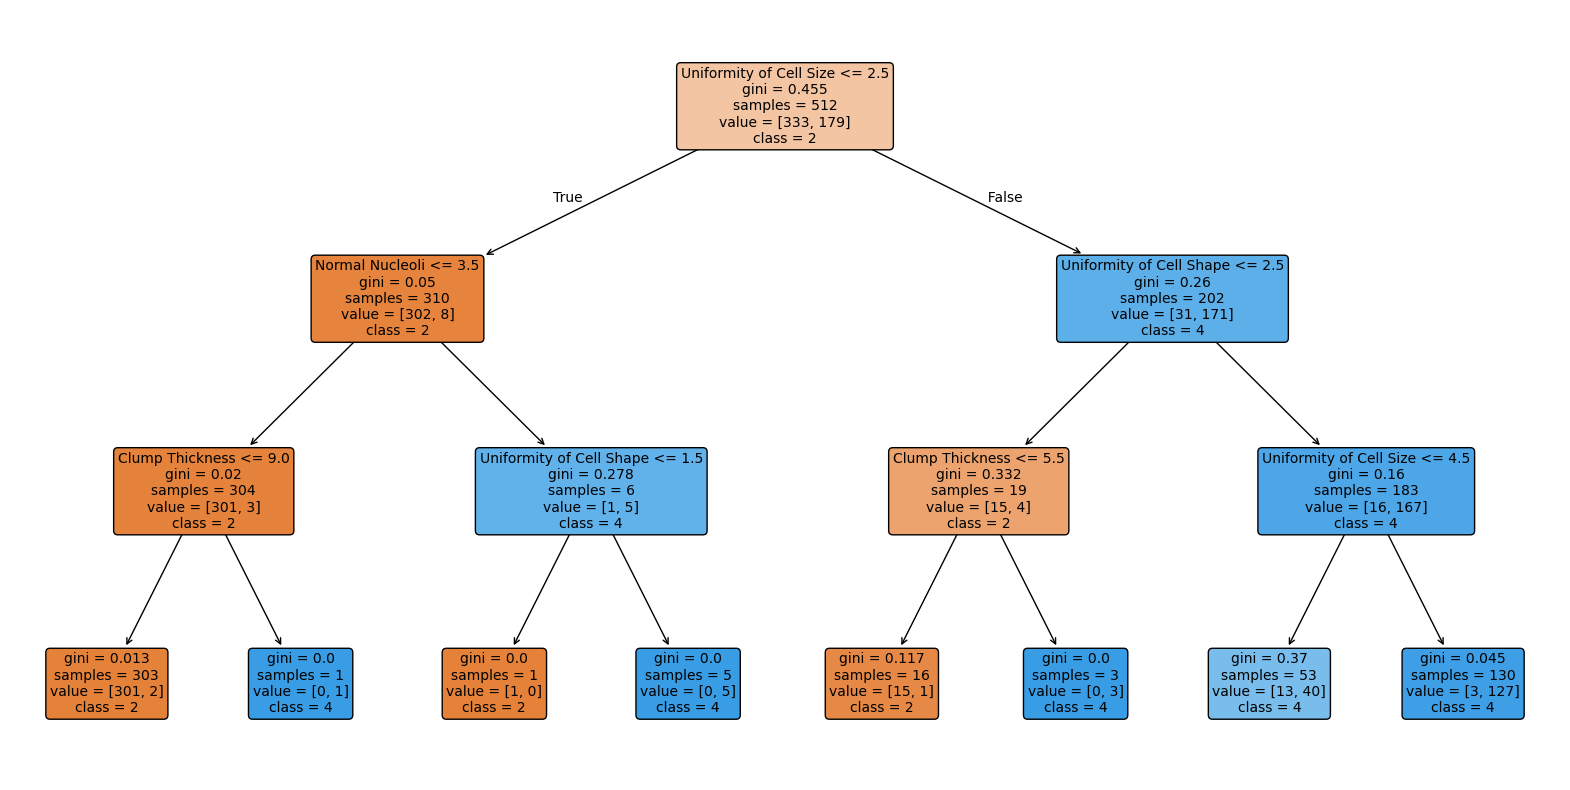

In [64]:
# Plot the Decision Tree
plt.figure(figsize = (20, 10))
plot_tree(clf, filled = True, feature_names = X.columns.tolist(), class_names = [str(label) for label in df['Class'].unique()], 
          rounded = True, fontsize = 10)
plt.show()

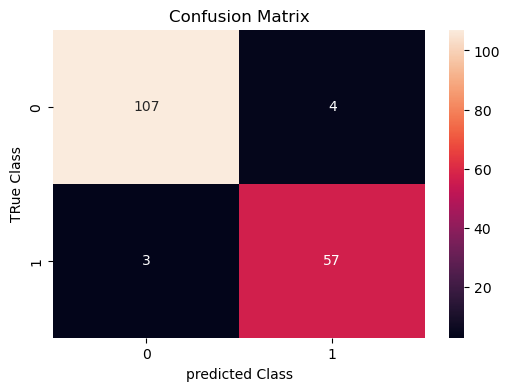

Classification Report:
              precision    recall  f1-score   support

           2       0.97      0.96      0.97       111
           4       0.93      0.95      0.94        60

    accuracy                           0.96       171
   macro avg       0.95      0.96      0.96       171
weighted avg       0.96      0.96      0.96       171



In [65]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

# Predict by using an object classifier 'clf'
y_predict = clf.predict(X_test)

# Calculate cm by using a method named as 'confusion_matrix'
cm = confusion_matrix(y_test, y_predict)

# Plot confusion matrix with integers using seaborn heatmap
plt.figure(figsize = (6, 4))
sns.heatmap(cm, annot = True, fmt = 'd')        # 'd' stands for integer format
plt.xlabel('predicted Class')
plt.ylabel('TRue Class')
plt.title('Confusion Matrix')
plt.show()

# Generate classification report
report = classification_report(y_test, y_predict)
print("Classification Report:")
print(report)

como podemos observar en la evaluacion de random forest, las columnas tienen una ccruracy muy parecida, siendo 15% la mejor.:

1 - 5% = reconocio 33 aciertos, 21 muestras benignas y 12 malignas. a su vez reconocio 2 errores una muestra benigna predicha como maligna y una maligna predicha como benigna en total 32 aciertos +2 errores el accuracy fue 94.29%

2- 15% = reconocio 99 aciertos. 63 muestras benignas y 36 Malignas. a su vez reconocio 3 errores en benignas predichas como malignas y una maligna predicha como benigna. en total de los 99 aciertos + 4 errores accuracy fue 96.12%

3- 25% = reconocio 152 aciertos. 107 muestra benignas y 56 malignas, a su vez  reconocio 4 malignas predichas como benignas y 4 Malignas predichas como benignas. en total de los 152 aciertos + 8 errores accuracy fue 95.32% 

el 15% de prueba obtuvo la mayor accuracy en los datos reservados con el 96,12% Ademas, clasifico correctamente 36 de 37 muestras malignas.

## Random Forest - 5% Test Split    Archivo utilizado CASE_Studio_LR 

In [66]:
from sklearn.ensemble import RandomForestClassifier
models = {"Random Forest": RandomForestClassifier(n_estimators = 100, random_state = 42)}

In [67]:
from sklearn.model_selection import train_test_split, cross_val_score

# Reserve 5% for testing and use 95% for training
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.05, random_state=1
)

results = []

for name, model in models.items():
    scores = cross_val_score(
        model, X_train, y_train, cv=5, scoring="accuracy"
    )
    results.append([name, scores.mean(), scores.std()])

results_05 = pd.DataFrame(
    results, columns=["Model", "Mean CV Accuracy", "CV Accuracy Std"]
)
results_05

,Model,Mean CV Accuracy,CV Accuracy Std
0,Random Forest,0.972212,0.015106


## Random Forest - 15% Test Split

In [68]:
from sklearn.ensemble import RandomForestClassifier
models = {"Random Forest": RandomForestClassifier(n_estimators = 100, random_state = 42)}

In [69]:
from sklearn.model_selection import train_test_split, cross_val_score

# Reserve 15% for testing and use 85% for training
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.15, random_state=1
)

results = []

for name, model in models.items():
    scores = cross_val_score(
        model, X_train, y_train, cv=5, scoring="accuracy"
    )
    results.append([name, scores.mean(), scores.std()])

results_15 = pd.DataFrame(
    results, columns=["Model", "Mean CV Accuracy", "CV Accuracy Std"]
)
results_15

,Model,Mean CV Accuracy,CV Accuracy Std
0,Random Forest,0.963793,0.016716


## Random Forest - 25% Test Split 

In [70]:
from sklearn.ensemble import RandomForestClassifier
models = {"Random Forest": RandomForestClassifier(n_estimators = 100, random_state = 42)}

In [71]:
from sklearn.model_selection import train_test_split, cross_val_score

# Reserve 25% for testing and use 75% for training
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=1
)

results = []

for name, model in models.items():
    scores = cross_val_score(
        model, X_train, y_train, cv=5, scoring="accuracy"
    )
    results.append([name, scores.mean(), scores.std()])

results_25 = pd.DataFrame(
    results, columns=["Model", "Mean CV Accuracy", "CV Accuracy Std"]
)
results_25

,Model,Mean CV Accuracy,CV Accuracy Std
0,Random Forest,0.960956,0.010655


como podemos observar la accuracy media estuvo entre 96,10% y 97.07% entre los 3 modelos de random forest. en este caso el 5% obtuvo la media mas alta con 97,07% y tambien mostro la mayor variacion entre los 5 fold. la diferencia entre la media mas alta y la mas baja fue de menos de un punto porcentual 


## Linear Regression 

In [72]:
df_new.head(10)

,Clump Thickness,Uniformity of Cell Size,Uniformity of Cell Shape,Marginal Adhesion,Single Epithelial Cell Size,Bare Nuclei,Bland Chromatin,Normal Nucleoli,Mitoses,Class
0,5,1,1,1,2,1,3,1,1,2
1,5,4,4,5,7,10,3,2,1,2
2,3,1,1,1,2,2,3,1,1,2
3,6,8,8,1,3,4,3,7,1,2
4,4,1,1,3,2,1,3,1,1,2
5,8,10,10,8,7,10,9,7,1,4
6,1,1,1,1,2,10,3,1,1,2
7,2,1,2,1,2,1,3,1,1,2
8,2,1,1,1,2,1,1,1,5,2
9,4,2,1,1,2,1,2,1,1,2


In [73]:
df_new_means = df_new['Class'].mean()

df_new_means

2.6998535871156664

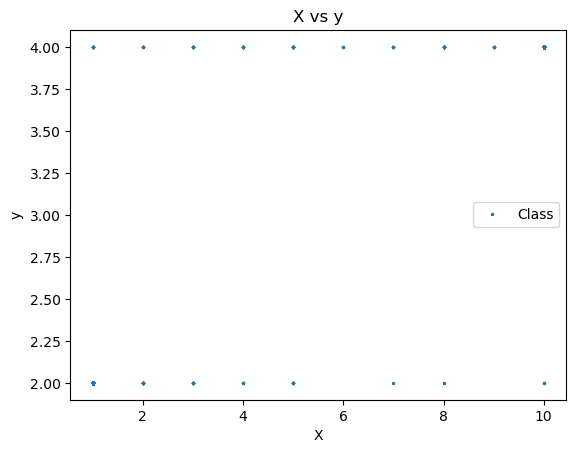

In [74]:
df_new.plot(x="Bare Nuclei", y='Class', style='*', markersize=2)
plt.title('X vs y')
plt.xlabel('X')
plt.ylabel('y')
plt.show()

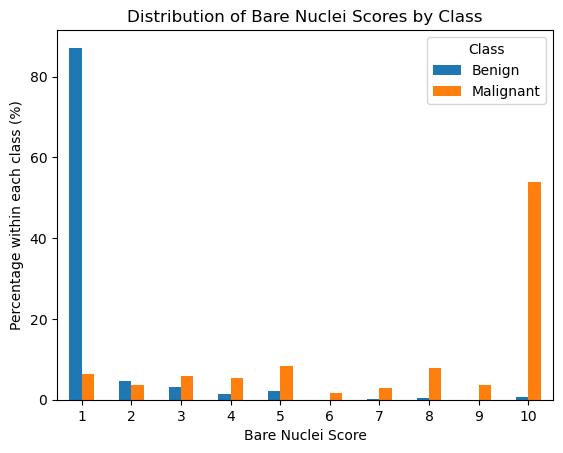

In [75]:
porcentajes = pd.crosstab(
    df_new["Bare Nuclei"],
    df_new["Class"],
    normalize="columns"
) * 100

porcentajes = porcentajes.rename(columns={2: "Benign", 4: "Malignant"})
porcentajes.plot(kind="bar", rot=0)

plt.title("Distribution of Bare Nuclei Scores by Class")
plt.xlabel("Bare Nuclei Score")
plt.ylabel("Percentage within each class (%)")
plt.show()

In [76]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.05, random_state=1
)

In [77]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

logistic_model = LogisticRegression(max_iter=1000)
logistic_model.fit(X_train, y_train)

y_pred_logistic = logistic_model.predict(X_test)
print(f"Test accuracy: {accuracy_score(y_test, y_pred_logistic):.2%}")

Test accuracy: 97.14%


In [78]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.15, random_state=1
)

In [79]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

logistic_model = LogisticRegression(max_iter=1000)
logistic_model.fit(X_train, y_train)

y_pred_logistic = logistic_model.predict(X_test)
print(f"Test accuracy: {accuracy_score(y_test, y_pred_logistic):.2%}")

Test accuracy: 98.06%


In [80]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=1
)

In [81]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

logistic_model = LogisticRegression(max_iter=1000)
logistic_model.fit(X_train, y_train)

y_pred_logistic = logistic_model.predict(X_test)
print(f"Test accuracy: {accuracy_score(y_test, y_pred_logistic):.2%}")

Test accuracy: 98.25%


In [82]:
from sklearn.linear_model import LogisticRegression
logistic_models = {"Logistic Regression": LogisticRegression(max_iter = 1000, random_state = 42),}

In [83]:
# Reserve 0.5% for testing and use 95% for training
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.05, random_state=1
)

results = []

for name, model in logistic_models.items():
    scores = cross_val_score(
        model, X_train, y_train, cv=5, scoring="accuracy"
    )
    results.append([name, scores.mean(), scores.std()])

results_5 = pd.DataFrame(
    results, columns=["Model", "Mean CV Accuracy", "CV Accuracy Std"]
)
results_5

,Model,Mean CV Accuracy,CV Accuracy Std
0,Logistic Regression,0.967609,0.017173


In [84]:
# Reserve 0.5% for testing and use 95% for training
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.15, random_state=1
)

results = []

for name, model in logistic_models.items():
    scores = cross_val_score(
        model, X_train, y_train, cv=5, scoring="accuracy"
    )
    results.append([name, scores.mean(), scores.std()])

results_15 = pd.DataFrame(
    results, columns=["Model", "Mean CV Accuracy", "CV Accuracy Std"]
)
results_15

,Model,Mean CV Accuracy,CV Accuracy Std
0,Logistic Regression,0.963793,0.013793


In [85]:
# Reserve 0.5% for testing and use 95% for training
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=1
)

results = []

for name, model in logistic_models.items():
    scores = cross_val_score(
        model, X_train, y_train, cv=5, scoring="accuracy"
    )
    results.append([name, scores.mean(), scores.std()])

results_25 = pd.DataFrame(
    results, columns=["Model", "Mean CV Accuracy", "CV Accuracy Std"]
)
results_25

,Model,Mean CV Accuracy,CV Accuracy Std
0,Logistic Regression,0.962955,0.018823


## validación cruzada de regresión

In [86]:
classifiers = {
    "Random Forest": RandomForestClassifier(n_estimators = 100, random_state = 42),
    "Logistic Regression": LogisticRegression(max_iter = 1000, random_state = 42),
}

In [87]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=1
)

In [88]:
results = []
for name, classifier in classifiers.items():
    # Train the classifier
    classifier.fit(X_train, y_train)
    
    # Predict on the test set
    y_pred = classifier.predict(X_test)
    
    # Calculate performance metrics
    accuracy = accuracy_score(y_test, y_pred)
    report = classification_report(y_test, y_pred, output_dict=True)
    precision = report['weighted avg']['precision']
    recall = report['weighted avg']['recall']
    f1_score = report['weighted avg']['f1-score']
    
    # Append results
    results.append([name, accuracy, precision, recall, f1_score])

In [89]:
# Convert results to DataFrame for easy viewing
results_df = pd.DataFrame(results, columns=["Model", "Accuracy", "Precision", "Recall", "F1 Score"])
print("Model Performance Metrics on Test Set:")
print(results_df)   

Model Performance Metrics on Test Set:
                 Model  Accuracy  Precision    Recall  F1 Score
0        Random Forest  1.000000   1.000000  1.000000  1.000000
1  Logistic Regression  0.982456   0.982918  0.982456  0.982348


## 2

In [90]:
classifiers = {
    "Random Forest": RandomForestClassifier(n_estimators = 100, random_state = 42),
    "Logistic Regression": LogisticRegression(max_iter = 1000, random_state = 42),
}

In [91]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.15, random_state=1
)

In [92]:
results = []
for name, classifier in classifiers.items():
    # Train the classifier
    classifier.fit(X_train, y_train)
    
    # Predict on the test set
    y_pred = classifier.predict(X_test)
    
    # Calculate performance metrics
    accuracy = accuracy_score(y_test, y_pred)
    report = classification_report(y_test, y_pred, output_dict=True)
    precision = report['weighted avg']['precision']
    recall = report['weighted avg']['recall']
    f1_score = report['weighted avg']['f1-score']
    
    # Append results
    results.append([name, accuracy, precision, recall, f1_score])

In [93]:
# Convert results to DataFrame for easy viewing
results_df = pd.DataFrame(results, columns=["Model", "Accuracy", "Precision", "Recall", "F1 Score"])
print("Model Performance Metrics on Test Set:")
print(results_df)   

Model Performance Metrics on Test Set:
                 Model  Accuracy  Precision    Recall  F1 Score
0        Random Forest  0.990291   0.990436  0.990291  0.990261
1  Logistic Regression  0.980583   0.981154  0.980583  0.980458


## 3

In [94]:
classifiers = {
    "Random Forest": RandomForestClassifier(n_estimators = 100, random_state = 42),
    "Logistic Regression": LogisticRegression(max_iter = 1000, random_state = 42),
}

In [95]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.05, random_state=1
)

In [96]:
results = []
for name, classifier in classifiers.items():
    # Train the classifier
    classifier.fit(X_train, y_train)
    
    # Predict on the test set
    y_pred = classifier.predict(X_test)
    
    # Calculate performance metrics
    accuracy = accuracy_score(y_test, y_pred)
    report = classification_report(y_test, y_pred, output_dict=True)
    precision = report['weighted avg']['precision']
    recall = report['weighted avg']['recall']
    f1_score = report['weighted avg']['f1-score']
    
    # Append results
    results.append([name, accuracy, precision, recall, f1_score])

In [97]:
# Convert results to DataFrame for easy viewing
results_df = pd.DataFrame(results, columns=["Model", "Accuracy", "Precision", "Recall", "F1 Score"])
print("Model Performance Metrics on Test Set:")
print(results_df)   

Model Performance Metrics on Test Set:
                 Model  Accuracy  Precision    Recall  F1 Score
0        Random Forest  0.942857   0.947619  0.942857  0.941718
1  Logistic Regression  0.971429   0.972671  0.971429  0.971175
